In [1]:
import pandas as pd
from pathlib import Path

In [4]:
# Desktop loading
DATA_ROOT = Path(
    r"../data/"
)

In [3]:
def load_market_data(
    exchange,
    symbol,
    data_type="book",
    date=None,
):
    path = (
        DATA_ROOT
        / exchange.upper()
        / symbol.upper()
        / data_type
    )

    if date is not None:
        path = path / date

    if not path.exists():
        raise FileNotFoundError(
            f"No data found at:\n{path}"
        )

    df = pd.read_parquet(path)

    return df

In [15]:
hl_pendle = load_market_data(
    "HYPERLIQUID",
    "PENDLE-USD-PERP",
    "book"
)

binance_pendle = load_market_data(
    "BINANCE",
    "PENDLE-USDT",
    "book"
)


In [16]:
hl_pendle.head(1)

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
0,HYPERLIQUID,PENDLE-USD-PERP,2.3816,58.0,2.3823,163.0,2.38195,0.0007,2.938769,-0.475113,2.381784,1.790640e+09,1.790640e+09


In [17]:
b = binance_pendle.copy()

b["datetime"] = pd.to_datetime(
    b["receipt_timestamp"],
    unit="s",
    utc=True
)

b = (
    b
    .set_index("datetime")
    .sort_index()
)

h = hl_pendle.copy()

h["datetime"] = pd.to_datetime(
    h["receipt_timestamp"],
    unit="s",
    utc=True
)

h = (
    h
    .set_index("datetime")
    .sort_index()
)

In [22]:
b.head()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
datetime,,,,,,,,,,,,,
2026-09-28 07:39:28.599307299+00:00,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,NaN,1.790581e+09
2026-09-28 07:39:28.599591494+00:00,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,1.790581e+09,1.790581e+09
2026-09-28 07:39:28.624696732+00:00,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,1.790581e+09,1.790581e+09
2026-09-28 07:39:28.825083017+00:00,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,1.790581e+09,1.790581e+09
2026-09-28 07:39:29.324463129+00:00,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,1.790581e+09,1.790581e+09


In [23]:
h.head()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
datetime,,,,,,,,,,,,,
2026-09-28 07:39:27.913859129+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4409,458.0,2.4419,94.0,2.44140,0.0010,4.096010,0.659420,2.441730,1.790581e+09,1.790581e+09
2026-09-28 07:39:28.554440975+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4410,654.0,2.4419,94.0,2.44145,0.0009,3.686334,0.748663,2.441787,1.790581e+09,1.790581e+09
2026-09-28 07:39:34.025192738+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4426,654.0,2.4432,94.0,2.44290,0.0006,2.456097,0.748663,2.443125,1.790581e+09,1.790581e+09
2026-09-28 07:39:39.122505426+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4424,654.0,2.4433,95.0,2.44285,0.0009,3.684221,0.746328,2.443186,1.790581e+09,1.790581e+09
2026-09-28 07:39:44.699936867+00:00,HYPERLIQUID,PENDLE-USD-PERP,2.4430,654.0,2.4436,204.0,2.44330,0.0006,2.455695,0.524476,2.443457,1.790581e+09,1.790581e+09


In [38]:
# Include both 'mid' and 'bid' in the selection filter
b_100ms = (
    b[["mid", "bid", 'ask', 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("100ms")
    .last()
    .ffill()
    .rename(columns={"mid": "bin_mid", "bid": "bin_bid", 
                    'bid_size':'bid_size_bin', 'ask_size':'ask_size_bin',
                    'imbalance':'imbalance_bin', 'microprice':'microprice_bin'})
)

h_100ms = (
    h[["mid", "bid", 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("100ms")
    .last()
    .ffill()
    .rename(columns={"mid": "hl_mid", "bid": "hl_bid",
                    'bid_size':'bid_size_hl', 'ask_size':'ask_size_hl',
                    'imbalance':'imbalance_hl', 'microprice':'microprice_hl'})
)

# Merge them on their timestamp indexes
df = b_100ms.join(h_100ms, how="inner")
df.head()

,bin_mid,bin_bid,ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl
datetime,,,,,,,,,,,,,
2026-09-28 07:39:28.500000+00:00,2.4405,2.44,2.441,533.7,423.0,0.11571,2.440558,2.44145,2.441,654.0,94.0,0.748663,2.441787
2026-09-28 07:39:28.600000+00:00,2.4405,2.44,2.441,533.7,423.0,0.11571,2.440558,2.44145,2.441,654.0,94.0,0.748663,2.441787
2026-09-28 07:39:28.700000+00:00,2.4405,2.44,2.441,533.7,423.0,0.11571,2.440558,2.44145,2.441,654.0,94.0,0.748663,2.441787
2026-09-28 07:39:28.800000+00:00,2.4405,2.44,2.441,533.7,423.0,0.11571,2.440558,2.44145,2.441,654.0,94.0,0.748663,2.441787
2026-09-28 07:39:28.900000+00:00,2.4405,2.44,2.441,533.7,423.0,0.11571,2.440558,2.44145,2.441,654.0,94.0,0.748663,2.441787


In [57]:
df['microprice_diff'] = df['microprice_hl'] - df['microprice_bin']
df["mid_diff"] = (
    df["hl_mid"]
    - df["bin_mid"]
)

df["reference_mid"] = (
    df["hl_mid"]
    + df["bin_mid"]
) / 2

df["mid_diff_bps"] = (
    df["hl_mid"]
    - df["bin_mid"]
) / df["reference_mid"] * 10_000

# Get EMA calculation

<Axes: xlabel='datetime'>

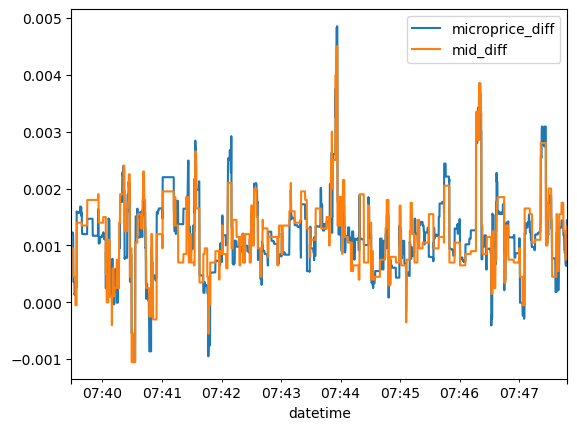

In [48]:
df[['microprice_diff', 'mid_diff']].iloc[0:5_000].plot()

In [56]:
df[['microprice_diff', 'mid_diff']].describe()

,microprice_diff,mid_diff
count,2.604267e+06,2.604267e+06
mean,1.938843e-04,1.820328e-04
std,1.253291e-03,1.260340e-03
min,-1.734579e-02,-1.695000e-02
25%,-6.877254e-04,-6.500000e-04
50%,1.444702e-04,1.500000e-04
75%,1.014954e-03,1.000000e-03
max,2.281046e-02,2.290000e-02


shouldn't the above be more or less the same? it looks like, if anything, they are reversed?